# Physics-Informed Neural Network for the 1-D Heat Equation

This notebook solves the 1-D heat equation with a **physics-informed neural network (PINN)** and compares it with an ordinary neural network trained on observed data alone.

## Problem

$$
u_t = k\,u_{xx}, \qquad 0<x<1,\quad 0<t<100,\quad k = 0.003
$$

with

$$
u(0,t) = u(1,t) = 0, \qquad u(x,0) = 50\,x(1-x).
$$

An exact solution exists (a Fourier sine series), so every model can be scored against the truth.

## Workflow

1. **Standard neural network.** Fit noise-free observations of the solution from the early part of the time domain ($t \le 20$). It matches the data but has no knowledge of the physics, so it cannot extrapolate to later times.
2. **PINN.** Use *no interior observations at all*. Only the initial condition, the boundary conditions and the PDE residual at randomly placed collocation points enter the loss. The PINN predicts the whole domain.
3. **Compare** both against the exact solution.

The companion notebook, `02_pinn_robustness_fgsm.ipynb`, tests how both models respond to adversarial perturbations of their inputs.

> Method: Raissi, Perdikaris and Karniadakis, *Physics-informed neural networks*, Journal of Computational Physics (2019).

In [1]:
import time
import numpy as np
import torch
import matplotlib.pyplot as plt

import heat_pinn as hp

SEED = 123
torch.manual_seed(SEED)
np.random.seed(SEED)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": False})
print("torch", torch.__version__)

torch 2.14.1+cu130


## 1. Exact solution and training data

The exact solution is evaluated on a $501 \times 501$ grid. It is used for the observations given to the standard network and as the reference for scoring.

In [2]:
k = hp.K
x = np.linspace(*hp.X_RANGE, 501)
t = np.linspace(*hp.T_RANGE, 501)
u_exact = hp.exact_solution_grid(x, t, k)           # shape (len(x), len(t))
print("exact solution grid:", u_exact.shape, "| max u =", round(u_exact.max(), 3))

# Everything the models are evaluated on
test_xt = hp.grid_inputs(x, t)                       # (251001, 2)

exact solution grid: (501, 501) | max u = 12.5


### Which points does each model see?

| Model | Loss terms | Points |
|---|---|---|
| Standard NN | data misfit | observations on a coarse grid for $t \le 20$ only (`T_DATA_MAX`) |
| PINN | initial condition + boundary conditions + PDE residual | $u(x,0)$ from the known formula, $u=0$ at $x=0,1$, and random collocation points over the **whole** domain |

The PINN is never shown a single interior observation of the solution.

In [3]:
T_DATA_MAX = 20.0          # observations only exist for t <= T_DATA_MAX

# --- Standard NN: sparse observations in the early-time window -------------
xi = np.arange(0, 501, 5)                                   # every 5th x  -> 101 points
tj = np.arange(0, int(T_DATA_MAX / (hp.T_RANGE[1] / 500)) + 1, 5)   # every 5th t in the window
data_xt = hp.grid_inputs(x[xi], t[tj])
data_u = hp.to_column(u_exact[np.ix_(xi, tj)])
print("observations for the standard NN:", tuple(data_xt.shape))

# --- PINN: initial condition ----------------------------------------------
x_ic = np.linspace(*hp.X_RANGE, 101)
ic_xt = hp.grid_inputs(x_ic, [0.0])
ic_u = hp.to_column(hp.initial_condition(x_ic))

# --- PINN: boundary conditions (u = 0 at x = 0 and x = 1) ------------------
t_bc = np.linspace(*hp.T_RANGE, 101)
bc_left_xt = hp.grid_inputs([hp.X_RANGE[0]], t_bc)
bc_right_xt = hp.grid_inputs([hp.X_RANGE[1]], t_bc)

# --- PINN: collocation points for the PDE residual ------------------------
N_COLLOC = 4000
rng = np.random.default_rng(SEED)
colloc_xt = torch.tensor(
    np.column_stack([rng.uniform(*hp.X_RANGE, N_COLLOC), rng.uniform(*hp.T_RANGE, N_COLLOC)]),
    dtype=torch.float32)

print("IC:", tuple(ic_xt.shape), "| BC:", tuple(bc_left_xt.shape), "+", tuple(bc_right_xt.shape),
      "| collocation:", tuple(colloc_xt.shape))

observations for the standard NN: (2121, 2)
IC: (101, 2) | BC: (101, 2) + (101, 2) | collocation: (4000, 2)


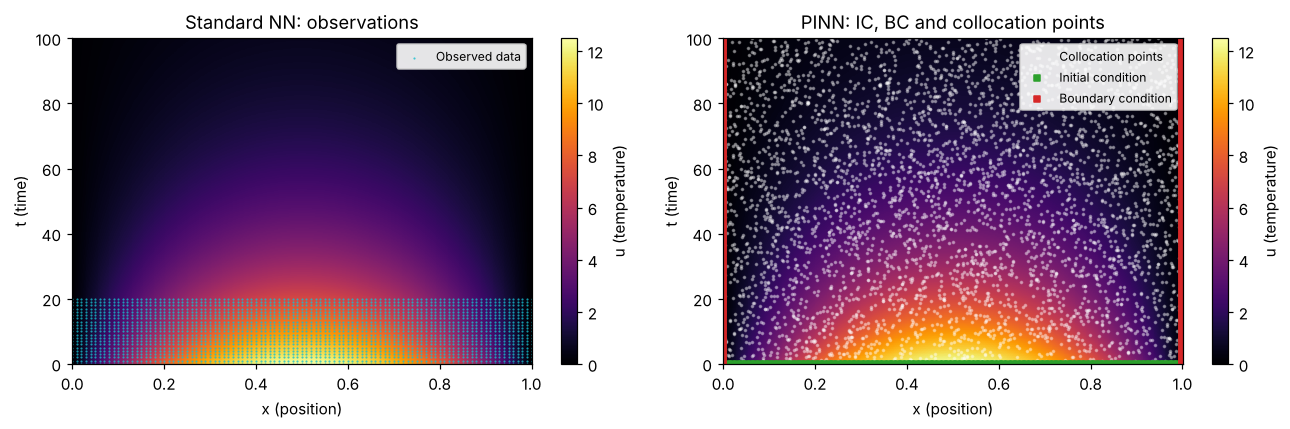

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
hp.plot_data_layout(x, t, u_exact, data_xt=data_xt, ax=axes[0])
axes[0].set_title("Standard NN: observations")
hp.plot_data_layout(x, t, u_exact, ic_xt=ic_xt, colloc_xt=colloc_xt, ax=axes[1])
axes[1].scatter(bc_left_xt[:, 0], bc_left_xt[:, 1], s=14, c="tab:red", marker="s", label="Boundary condition")
axes[1].scatter(bc_right_xt[:, 0], bc_right_xt[:, 1], s=14, c="tab:red", marker="s")
axes[1].legend(loc="upper right", fontsize=8, framealpha=0.9)
axes[1].set_title("PINN: IC, BC and collocation points")
fig.tight_layout()
fig.savefig("figures/training_points.png", bbox_inches="tight")
plt.show()

## 2. Standard neural network

A fully connected network $u_\theta(x,t)$ (4 hidden layers of 20 tanh units) is fitted to the observations by minimising the mean squared error:

$$
\mathcal{L}_{\text{NN}}(\theta) = \frac{1}{N_d}\sum_{i=1}^{N_d} \big(u_\theta(x_i,t_i) - u_i\big)^2 .
$$

In [5]:
def train_standard_nn(n_steps=10_000, lr=1e-2, seed=SEED):
    torch.manual_seed(seed)
    model = hp.FCN(n_hidden=20, n_layers=4)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=n_steps // 4, gamma=0.5)
    history = []
    start = time.time()
    for step in range(1, n_steps + 1):
        opt.zero_grad()
        loss = torch.mean((model(data_xt) - data_u) ** 2)
        loss.backward()
        opt.step()
        sched.step()
        history.append(loss.item())
        if step % 2000 == 0:
            print(f"step {step:6d} | data loss {loss.item():.3e} | {time.time() - start:5.1f}s")
    return model.eval(), history

model_nn, hist_nn = train_standard_nn()

step   2000 | data loss 9.942e-04 |   3.1s


step   4000 | data loss 4.065e-04 |   5.9s


step   6000 | data loss 2.826e-04 |   8.8s


step   8000 | data loss 2.107e-04 |  11.8s


step  10000 | data loss 1.650e-04 |  14.7s


## 3. Physics-informed neural network

The PINN has the same architecture, but its loss has three terms:

$$
\mathcal{L}_{\text{PINN}}(\theta) =
\underbrace{\tfrac{1}{N_0}\sum_i \big(u_\theta(x_i,0) - 50x_i(1-x_i)\big)^2}_{\text{initial condition}}
+ \underbrace{\tfrac{1}{N_b}\sum_j \big(u_\theta(0,t_j)^2 + u_\theta(1,t_j)^2\big)}_{\text{boundary conditions}}
+ \lambda\,\underbrace{\tfrac{1}{N_f}\sum_m \big(\partial_t u_\theta - k\,\partial_{xx} u_\theta\big)^2_{(x_m,t_m)}}_{\text{PDE residual}} .
$$

The derivatives $\partial_t u_\theta$ and $\partial_{xx} u_\theta$ come from automatic differentiation of the network with respect to its inputs (`heat_pinn.heat_residual`).

**Residual scaling.** In physical units the residual is tiny ($u_t \sim 10^{-2}$ while $u \sim 10$), so it is multiplied by the time span, $t_{\max}\,(u_t - k u_{xx})$. This only sets the weight of the residual term relative to the other two (an effective $\lambda = t_{\max}^2 = 10^4$ in the formula above, with the code's `lam=1`). It does not change the physics: the exact solution still has zero residual, so it remains the minimiser.

In [6]:
T_SPAN = hp.T_RANGE[1] - hp.T_RANGE[0]

def pinn_loss_terms(model, lam=1.0):
    loss_ic = torch.mean((model(ic_xt) - ic_u) ** 2)
    loss_bc = torch.mean(model(bc_left_xt) ** 2) + torch.mean(model(bc_right_xt) ** 2)
    residual = T_SPAN * hp.heat_residual(model, colloc_xt, k)      # rescaled, see text
    loss_pde = torch.mean(residual ** 2)
    return loss_ic, loss_bc, loss_pde, loss_ic + loss_bc + lam * loss_pde


def train_pinn(n_steps=15_000, lr=1e-2, lam=1.0, seed=SEED):
    torch.manual_seed(seed)
    model = hp.FCN(n_hidden=20, n_layers=4)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=n_steps // 5, gamma=0.5)
    history = {"ic": [], "bc": [], "pde": [], "total": []}
    start = time.time()
    for step in range(1, n_steps + 1):
        opt.zero_grad()
        l_ic, l_bc, l_pde, loss = pinn_loss_terms(model, lam)
        loss.backward()
        opt.step()
        sched.step()
        for key, val in zip(history, (l_ic, l_bc, l_pde, loss)):
            history[key].append(val.item())
        if step % 2000 == 0:
            print(f"step {step:6d} | IC {l_ic.item():.2e} | BC {l_bc.item():.2e} | "
                  f"PDE {l_pde.item():.2e} | {time.time() - start:5.1f}s")
    return model.eval(), history

model_pinn, hist_pinn = train_pinn()

step   2000 | IC 3.73e-03 | BC 4.81e-03 | PDE 7.98e-03 |  14.7s


step   4000 | IC 1.60e-03 | BC 1.29e-03 | PDE 1.22e-03 |  29.4s


step   6000 | IC 8.90e-03 | BC 6.13e-03 | PDE 1.03e-02 |  44.3s


step   8000 | IC 1.36e-03 | BC 5.20e-04 | PDE 7.67e-04 |  59.2s


step  10000 | IC 1.20e-03 | BC 4.74e-04 | PDE 4.48e-04 |  74.4s


step  12000 | IC 1.17e-03 | BC 4.92e-04 | PDE 6.43e-04 |  89.5s


step  14000 | IC 1.12e-03 | BC 5.18e-04 | PDE 6.11e-04 | 104.1s


## 4. Results

Both models are evaluated on the full $501 \times 501$ grid. The dashed line marks the end of the window in which the standard network saw data.

In [7]:
with torch.no_grad():
    pred_nn = model_nn(test_xt).numpy().reshape(u_exact.shape)
    pred_pinn = model_pinn(test_xt).numpy().reshape(u_exact.shape)

in_window = t <= T_DATA_MAX
rows = []
for name, pred in [("Standard NN", pred_nn), ("PINN", pred_pinn)]:
    rows.append((name,
                 hp.relative_l2(pred[:, in_window], u_exact[:, in_window]),
                 hp.relative_l2(pred[:, ~in_window], u_exact[:, ~in_window]),
                 hp.relative_l2(pred, u_exact)))

print(f"{'Relative L2 error':<20}{'t <= %g (data)' % T_DATA_MAX:>16}{'t > %g (extrap.)' % T_DATA_MAX:>18}{'whole domain':>15}")
for name, a, b, c in rows:
    print(f"{name:<20}{a:>16.2e}{b:>18.2e}{c:>15.2e}")

Relative L2 error     t <= 20 (data)  t > 20 (extrap.)   whole domain
Standard NN                 1.56e-03          3.65e-01       2.00e-01
PINN                        1.31e-03          9.19e-04       1.21e-03


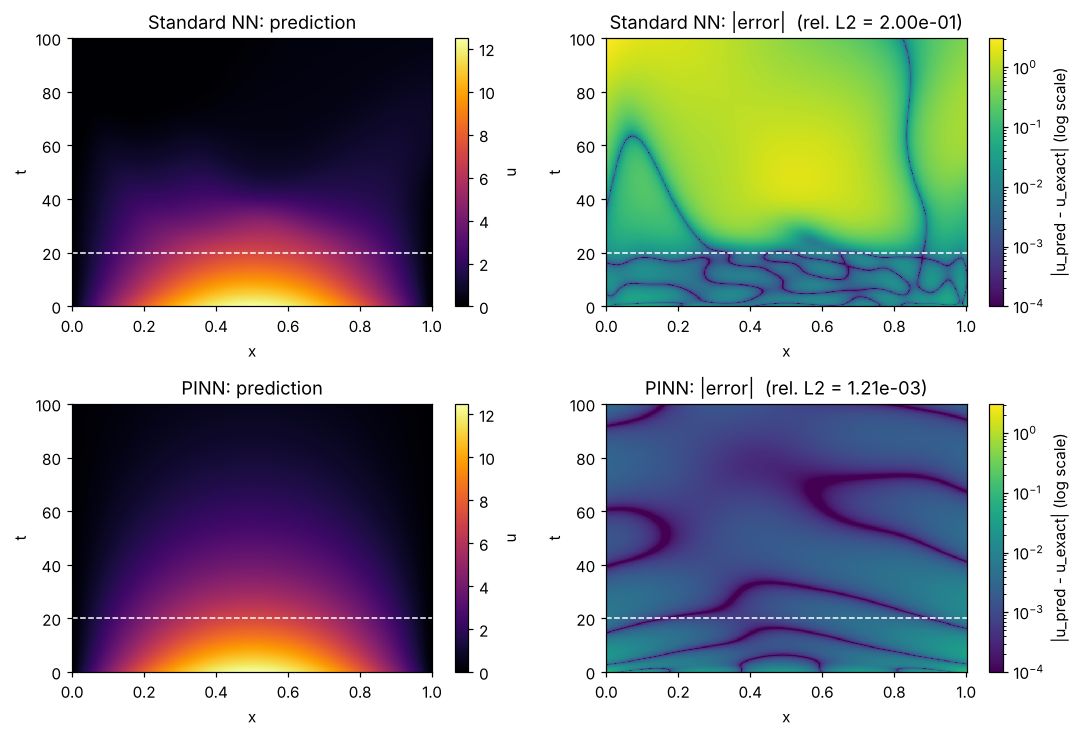

In [8]:
fig = hp.plot_comparison(x, t, u_exact, {"Standard NN": pred_nn, "PINN": pred_pinn}, data_t_max=T_DATA_MAX)
fig.savefig("figures/comparison_heatmaps.png", bbox_inches="tight")
plt.show()

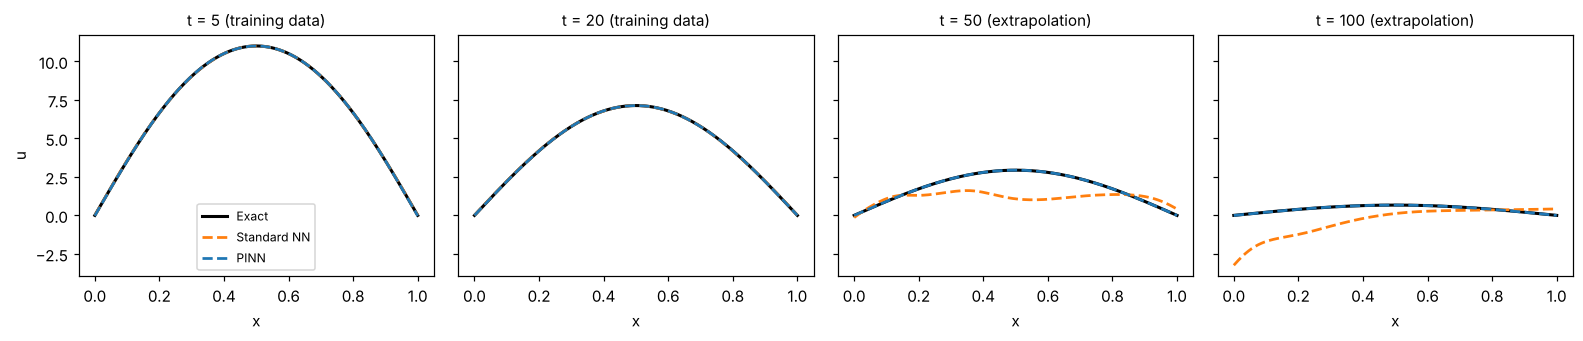

In [9]:
fig = hp.plot_slices(x, t, u_exact, {"Standard NN": pred_nn, "PINN": pred_pinn},
                     times=[5, 20, 50, 100], data_t_max=T_DATA_MAX)
fig.savefig("figures/comparison_slices.png", bbox_inches="tight")
plt.show()

The standard network reproduces the solution where it has data and then fails outside that window. The PINN is accurate over the full time range even though it never saw an interior observation, because the PDE residual forces it to follow the heat equation everywhere.

### Training curves

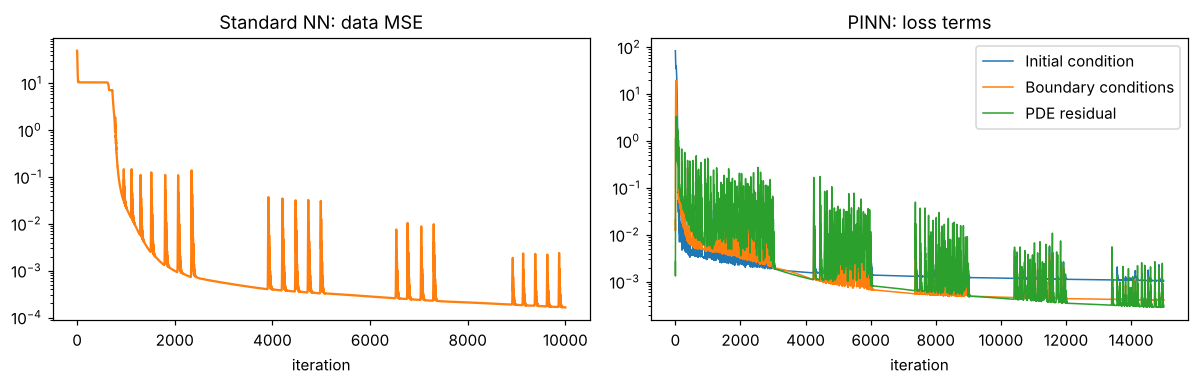

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].semilogy(hist_nn, color="tab:orange")
axes[0].set_title("Standard NN: data MSE")
axes[0].set_xlabel("iteration")
for key, label in [("ic", "Initial condition"), ("bc", "Boundary conditions"), ("pde", "PDE residual")]:
    axes[1].semilogy(hist_pinn[key], label=label, lw=1)
axes[1].set_title("PINN: loss terms")
axes[1].set_xlabel("iteration")
axes[1].legend()
fig.tight_layout()
fig.savefig("figures/training_curves.png", bbox_inches="tight")
plt.show()

## 5. Save the trained models

The weights are stored in `models/` and loaded by the second notebook for the robustness test.

In [11]:
hp.save_model(model_nn, "models/standard_nn.pt")
hp.save_model(model_pinn, "models/pinn.pt")
print("saved models/standard_nn.pt and models/pinn.pt")

saved models/standard_nn.pt and models/pinn.pt
